# Modelo v2: o conteúdo do Short ajuda a prever?

**Projeto Final · Machine Learning Clássico · Prof. Dr. Rodrigo Ramos Silva · 2026**

O modelo v1 (notebook `projeto_final_youtube_shorts.ipynb`) usou só metadados (duração, categoria, idioma e descrição)
e acertou o nível do canal, mas não a ordem dos vídeos. A pergunta deste notebook é se **olhar o conteúdo** muda isso:
a capa, o título, o roteiro falado e as cenas.

| Item | Escolha |
|---|---|
| Dados | mini dataset local: 383 Shorts de 54 canais faceless (es, en, de, fr, pt, ar), coletados com yt-dlp |
| Alvo | `viral` = 1 se o Short está no top 20% de views **dentro do próprio canal** (35,5% de positivos) |
| Features | 5 grupos: metadados, título, capa, roteiro e cenas (lista abaixo), cada uma menos a média do canal |
| Validação | validação cruzada aninhada com `GroupKFold` por canal: 5 dobras externas e 4 internas para o `GridSearchCV` |
| Modelos | Regressão Logística, KNN, Árvore de Decisão e Random Forest |
| Métrica | ROC AUC (média ± desvio nas 5 dobras externas) |
| Teste no mundo real | os 15 Shorts públicos do *Simulando o Mundo*: correlação de Spearman entre a nota e as views |

**Por que o alvo é dentro do canal:** num dataset de vários canais, o maior preditor de views é o tamanho do canal.
Comparando cada vídeo com os outros do mesmo canal, sobra o que muda de um vídeo para o outro.
E o `GroupKFold` garante que nenhum canal aparece no treino e no teste ao mesmo tempo.

**De onde vêm as features** (scripts em `src/v2/`, dados em `data/v2/`, fora do git):

| Grupo | Como | Exemplos |
|---|---|---|
| metadados | info do yt-dlp | duração, tamanho da descrição, hashtags, links, número de tags |
| título | expressões regulares | começa com "E se"/"What if", pergunta, "você", números, emojis, maiúsculas |
| capa | `capas.py`: capa vertical `oar2.jpg`, OpenCV | brilho, contraste, saturação, colorido (Hasler), cores quentes, áreas escuras, nitidez, bordas por faixa, rostos (Haar) |
| roteiro | legenda automática do YouTube na língua original do áudio, sem tradução (`.json3`, tempo por palavra); em vídeo dublado, a faixa original | palavras por minuto, primeira palavra, palavras nos 3 primeiros segundos, "você", números, variedade |
| cenas | `cenas.py`: histograma HSV a 4 quadros/s, Bhattacharyya; ECR e sons de um modelo de vídeo | cenas, cenas por minuto, plano médio, visuais distintos, ECR previsto, música, voz sintética |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore")

SEMENTE = 42
LARANJA, CINZA, TINTA = "#D96F1C", "#A39D94", "#262626"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DADOS = Path("../data/v2")
base = pd.read_csv(DADOS / "base_v2.csv")
sim = pd.read_csv(DADOS / "simulando_v2.csv")

GRUPOS = {
    "metadados": ["duracao_s", "desc_caracteres", "desc_hashtags", "desc_links", "desc_emojis", "n_tags"],
    "título": ["tit_caracteres", "tit_palavras", "tit_interrogacao", "tit_exclamacao", "tit_reticencias", "tit_numeros",
               "tit_maiusculas", "tit_emojis", "tit_hipotese", "tit_pergunta", "tit_voce", "tit_hashtags"],
    "capa": ["capa_brilho", "capa_contraste", "capa_saturacao", "capa_colorido", "capa_quente", "capa_escuro", "capa_nitidez",
             "capa_bordas", "capa_bordas_topo", "capa_bordas_meio", "capa_rostos", "capa_rosto_area"],
    "roteiro": ["rot_tem_legenda", "rot_palavras", "rot_palavras_min", "rot_inicio_s", "rot_palavras_3s", "rot_fala_frac",
                "rot_numeros", "rot_voce_100", "rot_variedade", "rot_tam_palavra"],
    "cenas": ["cen_cenas", "cen_cenas_min", "cen_plano_medio_s", "cen_distintas", "cen_mudanca_media",
              "cen_ecr", "cen_musica", "cen_voz_sintetica", "cen_narracao"],
}
TODAS = [c for cols in GRUPOS.values() for c in cols]


def relativo(tabela, colunas):
    # cada feature menos a média do próprio canal; NaN (ex.: legenda que o YouTube não entregou) fica NaN e é imputado
    rel = tabela.reindex(columns=colunas).astype(float)
    return rel - rel.groupby(tabela["canal"]).transform("mean")


y = (base["percentil"] >= 0.8).astype(int).values
g = base["canal"].values
X = relativo(base, TODAS)
print(f"{len(base)} Shorts, {base['canal'].nunique()} canais, {len(TODAS)} features; positivos: {y.mean():.1%}")

383 Shorts, 54 canais, 49 features; positivos: 35.5%


## 1. Os dados

Quantos vídeos por canal, e quanto de cada grupo de features existe de fato. Faltas: capas que o YouTube não serve,
vídeos sem legenda automática (sem fala, ou que o YouTube bloqueou no download) e vídeos que não deu para baixar para contar cenas.

In [2]:
por_canal = base.groupby("canal").size()
print(f"Shorts por canal: mediana {por_canal.median():.0f}, mínimo {por_canal.min()}, máximo {por_canal.max()}")
cobertura = pd.Series({gr: base[cols].notna().all(axis=1).mean() for gr, cols in GRUPOS.items()}).map("{:.0%}".format)
print("\nVídeos com o grupo completo:")
print(cobertura.to_string())

Shorts por canal: mediana 7, mínimo 6, máximo 12

Vídeos com o grupo completo:
metadados    100%
título       100%
capa          97%
roteiro       92%
cenas         94%


**Amostra dos dados**

Dez Shorts sorteados da base: cada linha é um vídeo de um canal faceless, com as views, o percentil de views dentro do próprio canal e uma feature de cada grupo (título, capa, roteiro e cenas).

In [ ]:
amostra = base.sample(10, random_state=SEMENTE)            # sorteio fixo: a tabela é sempre a mesma
amostra = pd.DataFrame({
    "canal": amostra["canal"],
    "título": amostra["titulo"].str.slice(0, 60),              # corta títulos longos
    "língua": amostra["lingua"],
    "duração (s)": amostra["duracao_s"],
    "views": amostra["views"],
    "percentil no canal": amostra["percentil"].round(2),
    "tit_hipotese": amostra["tit_hipotese"],                 # título em forma de hipótese ("e se...")
    "capa_brilho": amostra["capa_brilho"].round(2),
    "rot_palavras_min": amostra["rot_palavras_min"].round(0), # palavras faladas por minuto
    "cen_cenas_min": amostra["cen_cenas_min"].round(1),       # cortes de cena por minuto
})
amostra

,canal,título,língua,duração (s),views,percentil no canal,tit_hipotese,capa_brilho,rot_palavras_min,cen_cenas_min
268,Desmontando o Mundo,Como se constrói um arranha-céu? A engenharia ...,pt,148,5329558,0.82,0,0.43,192.0,21.6
250,Technik in 60 Sekunden,"Was wäre, wenn ganz Deutschland seine Schaufen...",de,65,1045,0.08,1,0.22,138.0,12.0
318,Pero Eso No Es Nada,La solución que salvó a una aldea entera bajo ...,es,119,30018,0.79,0,0.61,191.0,14.1
331,HirnWirbel,"Die 5 stärksten Atombomben, die jemals gezünde...",de,101,344049,0.87,0,0.67,149.0,22.5
56,Expliqué avec minecraft,Le fascisme expliqué avec minecraft,fr,89,294209,0.97,0,0.73,210.0,31.0
371,Geschichten über Deutschland,Das Geheimnis hinter Deutschlands Aufstieg #g...,de,152,313718,0.82,0,0.56,135.0,15.0
33,mundoElectricidadCurioso,Cómo funciona un transformador (y por qué no s...,es,57,254265,0.97,0,0.84,156.0,4.2
114,Historias Bestiales,Este lagarto dispara sangre por los ojos,es,47,5767,0.03,0,0.19,180.0,5.1
374,Yo te lo cuento fácil,El TRUCO OCULTO de las máquinas de GANCHO 🤯,es,52,6339,0.56,0,0.76,192.0,25.4
238,Situaciones Por Experimentar,¿Qué pasaría si la Tierra girara el doble de r...,es,53,104685,0.60,0,0.49,181.0,14.8


## 2. Cada feature sozinha, dentro do canal

Antes de treinar, a correlação de Spearman de cada feature relativa (menos a média do canal) com o percentil de views
no canal. Isto mostra onde há algum sinal, sem modelo nenhum.

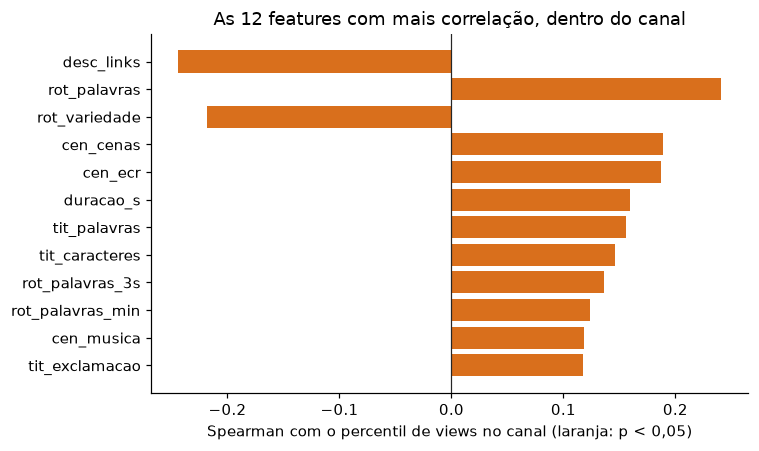

,grupo,feature,rho,p
3,metadados,desc_links,-0.244,0.000
31,roteiro,rot_palavras,0.241,0.000
38,roteiro,rot_variedade,-0.218,0.000
40,cenas,cen_cenas,0.189,0.000
45,cenas,cen_ecr,0.188,0.000
0,metadados,duracao_s,0.159,0.002
7,título,tit_palavras,0.156,0.002
6,título,tit_caracteres,0.146,0.004
34,roteiro,rot_palavras_3s,0.136,0.011
32,roteiro,rot_palavras_min,0.123,0.021


In [3]:
linhas = []
for gr, cols in GRUPOS.items():
    for c in cols:
        r, p = spearmanr(X[c], base["percentil"], nan_policy="omit")
        linhas.append({"grupo": gr, "feature": c, "rho": r, "p": p})
uni = pd.DataFrame(linhas).dropna().sort_values("rho", key=abs, ascending=False)
top = uni.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top["feature"], top["rho"], color=[LARANJA if p < 0.05 else CINZA for p in top["p"]])
ax.axvline(0, color=TINTA, lw=0.8)
ax.set_xlabel("Spearman com o percentil de views no canal (laranja: p < 0,05)")
ax.set_title("As 12 features com mais correlação, dentro do canal")
plt.tight_layout(); plt.show()
uni.head(12).round(3)

As correlações mais fortes ficam perto de 0,2: dentro de um canal, os vídeos **com mais fala, mais cenas e mais longos**
vão um pouco melhor. Essas três coisas andam juntas (vídeo mais longo tem mais palavras e mais cortes).

In [4]:
print("cenas x duração (relativas):", round(spearmanr(X["cen_cenas"], X["duracao_s"], nan_policy="omit")[0], 2))
print("palavras x duração (relativas):", round(spearmanr(X["rot_palavras"], X["duracao_s"], nan_policy="omit")[0], 2))

cenas x duração (relativas): 0.48
palavras x duração (relativas): 0.81


## 3. Ablação: o que cada grupo acrescenta

Mesmo protocolo para tudo: validação cruzada aninhada por canal, com `GridSearchCV` dentro de cada dobra.
Primeiro os grupos somados um a um (começando pelos metadados, que é o que o v1 usava), depois cada grupo sozinho.

In [5]:
MODELOS = {
    "Regressão Logística": (LogisticRegression(max_iter=3000, class_weight="balanced"), {"m__C": [0.01, 0.1, 1]}),
    "KNN": (KNeighborsClassifier(), {"m__n_neighbors": [15, 31, 51]}),
    "Árvore de Decisão": (DecisionTreeClassifier(class_weight="balanced", random_state=SEMENTE),
                          {"m__max_depth": [2, 3, 5], "m__min_samples_leaf": [10, 20]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEMENTE, n_jobs=1),
                      {"m__max_depth": [3, 5, None], "m__min_samples_leaf": [5, 15]}),
}


def pipe(est):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler()), ("m", est)])


def cv_aninhada(Xs, nome):
    est, grade = MODELOS[nome]
    aucs = []
    for tr, te in GroupKFold(n_splits=5).split(Xs, y, g):
        busca = GridSearchCV(pipe(est), grade, scoring="roc_auc", cv=GroupKFold(n_splits=4), n_jobs=-1)
        busca.fit(Xs.iloc[tr], y[tr], groups=g[tr])
        aucs.append(roc_auc_score(y[te], busca.predict_proba(Xs.iloc[te])[:, 1]))
    return np.mean(aucs), np.std(aucs)


conjuntos = {"metadados (v1)": ["metadados"], "+ título": ["metadados", "título"], "+ capa": ["metadados", "título", "capa"],
             "+ roteiro": ["metadados", "título", "capa", "roteiro"], "tudo (+ cenas)": list(GRUPOS)}
conjuntos.update({f"só {gr}": [gr] for gr in GRUPOS})
abl = []
for rot, grs in conjuntos.items():
    cols = [c for gr in grs for c in GRUPOS[gr]]
    for nome in ["Random Forest", "Regressão Logística"]:
        m, s = cv_aninhada(X[cols], nome)
        abl.append({"conjunto": rot, "modelo": nome, "AUC": m, "dp": s})
abl = pd.DataFrame(abl)
tab = abl.pivot(index="conjunto", columns="modelo", values="AUC").loc[list(conjuntos)].round(3)
tab

modelo,Random Forest,Regressão Logística
conjunto,,
metadados (v1),0.562,0.570
+ título,0.551,0.558
+ capa,0.532,0.535
+ roteiro,0.548,0.574
tudo (+ cenas),0.580,0.577
só metadados,0.562,0.570
só título,0.488,0.498
só capa,0.518,0.490
só roteiro,0.566,0.595


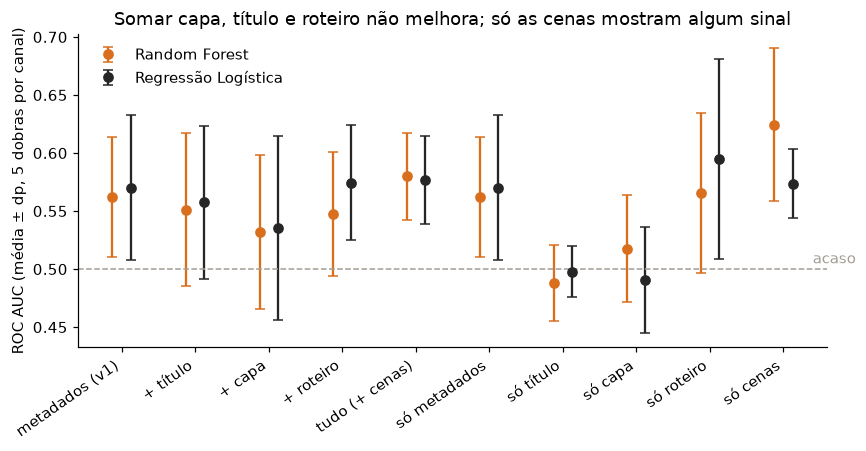

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ordem = list(conjuntos)
for i, nome in enumerate(["Random Forest", "Regressão Logística"]):
    d = abl[abl["modelo"] == nome].set_index("conjunto").loc[ordem]
    ax.errorbar(np.arange(len(ordem)) + (i - 0.5) * 0.25, d["AUC"], yerr=d["dp"], fmt="o", capsize=3,
                color=[LARANJA, TINTA][i], label=nome)
ax.axhline(0.5, color=CINZA, ls="--", lw=1)
ax.text(len(ordem) - 0.6, 0.505, "acaso", color=CINZA)
ax.set_xticks(range(len(ordem)), ordem, rotation=35, ha="right")
ax.set_ylabel("ROC AUC (média ± dp, 5 dobras por canal)")
ax.set_title("Somar capa, título e roteiro não melhora; só as cenas mostram algum sinal")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Os quatro modelos com todas as features

In [7]:
comp = pd.DataFrame([{"modelo": n, **dict(zip(["AUC", "dp"], cv_aninhada(X, n)))} for n in MODELOS]).round(3)
comp.sort_values("AUC", ascending=False)

,modelo,AUC,dp
3,Random Forest,0.580,0.038
0,Regressão Logística,0.577,0.038
2,Árvore de Decisão,0.551,0.055
1,KNN,0.546,0.075


As diferenças entre os modelos são menores que o desvio entre as dobras: com 383 vídeos e 49 features, nenhum se destaca.

## 5. De onde vem o sinal das cenas

O grupo de cenas mistura o ritmo de montagem (medido por nós), o ECR (previsto por um modelo de vídeo) e os sons.
Separando:

In [8]:
ritmo = ["cen_cenas", "cen_cenas_min", "cen_plano_medio_s", "cen_distintas", "cen_mudanca_media"]
partes = {"ritmo de montagem": ritmo, "só ECR": ["cen_ecr"], "sons": ["cen_musica", "cen_voz_sintetica", "cen_narracao"],
          "metadados + cenas": GRUPOS["metadados"] + GRUPOS["cenas"]}
pd.DataFrame([{"conjunto": k, "modelo": n, "AUC": round(cv_aninhada(X[v], n)[0], 3)}
              for k, v in partes.items() for n in ["Random Forest", "Regressão Logística"]]
             ).pivot(index="conjunto", columns="modelo", values="AUC").loc[list(partes)]

modelo,Random Forest,Regressão Logística
conjunto,,
ritmo de montagem,0.603,0.534
só ECR,0.516,0.594
sons,0.466,0.514
metadados + cenas,0.614,0.586


## 6. Importância por grupo

Random Forest treinado com todas as features; em cada dobra externa, embaralhamos as colunas de um grupo inteiro no teste
e medimos quanto o AUC cai (10 repetições). Grupo que não faz falta quando embaralhado não estava ajudando.

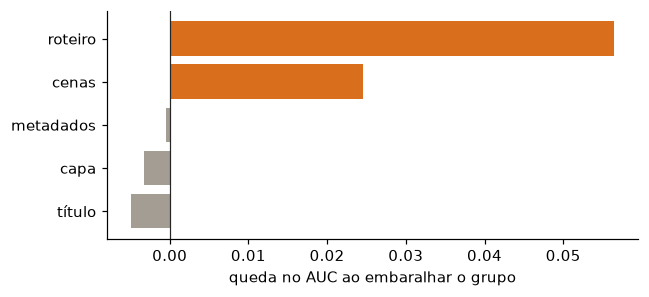

título      -0.0049
capa        -0.0033
metadados   -0.0005
cenas        0.0246
roteiro      0.0564
dtype: float64

In [9]:
est, grade = MODELOS["Random Forest"]
rng = np.random.default_rng(SEMENTE)
quedas = {gr: [] for gr in GRUPOS}
for tr, te in GroupKFold(5).split(X, y, g):
    busca = GridSearchCV(pipe(est), grade, scoring="roc_auc", cv=GroupKFold(4), n_jobs=-1).fit(X.iloc[tr], y[tr], groups=g[tr])
    ref = roc_auc_score(y[te], busca.predict_proba(X.iloc[te])[:, 1])
    for gr, cols in GRUPOS.items():
        for _ in range(10):
            Xp = X.iloc[te].copy()
            Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]
            quedas[gr].append(ref - roc_auc_score(y[te], busca.predict_proba(Xp)[:, 1]))
imp = pd.Series({gr: np.mean(v) for gr, v in quedas.items()}).sort_values()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(imp.index, imp.values, color=[LARANJA if v > 0.01 else CINZA for v in imp.values])
ax.axvline(0, color=TINTA, lw=0.8)
ax.set_xlabel("queda no AUC ao embaralhar o grupo")
plt.tight_layout(); plt.show()
imp.round(4)

## 7. Teste no canal *Simulando o Mundo*

Treinamos o modelo em toda a base e aplicamos aos 15 Shorts públicos do canal, com as features relativas à média do próprio canal.
O roteiro do canal vem da mesma fonte da base: a legenda automática do YouTube.

In [10]:
final = GridSearchCV(pipe(est), grade, scoring="roc_auc", cv=GroupKFold(5), n_jobs=-1).fit(X, y, groups=g)
sim["nota_v2"] = final.predict_proba(relativo(sim, TODAS))[:, 1]
rho, p = spearmanr(sim["nota_v2"], sim["views"])
print(f"Random Forest {final.best_params_}")
print(f"Spearman(nota v2, views) no canal: rho = {rho:.2f} (p = {p:.2f}, n = {len(sim)})")
print(sim.sort_values("nota_v2", ascending=False)[["titulo", "nota_v2"]].to_string(index=False, float_format="{:.2f}".format))

Random Forest {'m__max_depth': 3, 'm__min_samples_leaf': 15}
Spearman(nota v2, views) no canal: rho = -0.06 (p = 0.84, n = 15)
                                               titulo  nota_v2
                Como cocô de vaca vira gás de cozinha     0.62
             Como um buraco vira um posto de gasolina     0.59
  E se você pulasse num buraco que atravessa a Terra?     0.55
                E se o atrito sumisse por 5 segundos?     0.54
                            E se o Sol sumisse agora?     0.54
                E se o atrito sumisse por 5 segundos?     0.53
                 E se a Terra parasse de girar agora?     0.49
    E se você começasse a flutuar e não parasse mais?     0.48
       E se uma barra de tungstênio caísse do espaço?     0.46
        E se o Brasil inteiro pulasse ao mesmo tempo?     0.45
E se um terremoto subisse um ponto a cada 5 segundos?     0.43
        E se a gravidade dobrasse a cada 10 segundos?     0.42
                     E se a Lua sumisse hoje à noite? 

## 8. Conclusões do v2

1. **O conteúdo, do jeito que medimos, quase não ajuda.** Com o alvo dentro do canal, os metadados dão AUC ≈ 0,56–0,57 e, com
   as 49 features, fica em 0,58. Sozinhos, só as cenas (Random Forest ≈ 0,62) e o roteiro (Logística ≈ 0,60) passam disso.
2. **O sinal que existe é "mais conteúdo".** Dentro do canal, vídeos com mais fala, mais cenas e mais longos vão um pouco melhor
   (ρ ≈ 0,16–0,24), e essas medidas andam juntas.
3. **No canal, o v2 também não ordena os vídeos** (ρ perto de zero com as views).
4. **Uma armadilha de medição e uma surpresa.** Num teste rápido com legendas parciais, o AUC chegou a 0,78 porque
   "ter legenda" virou atalho para o download que deu certo; com as legendas completas, sumiu. E a capa desenhada pela
   pipeline nunca foi ao ar: os Shorts do canal foram publicados sem capa personalizada, então a capa real é um quadro do
   vídeo escolhido pelo YouTube (`oar2.jpg`), e é ela que o modelo mede.
5. **A língua da legenda importa.** O roteiro não é traduzido: cada vídeo é lido na língua original (9 línguas na base).
   Nos 37 vídeos dublados há uma legenda por faixa de áudio, e ler a faixa errada é ler uma tradução; a versão final usa a
   língua original registrada pelo yt-dlp.

**Limitações:** 383 vídeos em 54 canais é pouco para 49 features; as features de texto dependem da língua (por isso entram
relativas à média do canal); as features de imagem são clássicas (sem rede neural);
a base é de canais faceless de outros idiomas; ECR e sons vêm de um modelo de vídeo e não de dados reais de retenção.